In [68]:
# 1. Libraries
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

In [91]:
# 2. List the acquisitions to compare (2D prefix, before _Zone01.txt)
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp")
prefixes = [
    #"26-11-09_00022_TDC_2D_chopper1",
    #"26-11-09_00028_TDC_2D_chopper1",
    "26-11-09_00045_TDC_2D_chopper",
]
zones = np.arange(1, 7)
radial_folder = output_folder / "radial"
azimuthal_folder = output_folder / "azimuthal"
for folder in (output_folder, radial_folder, azimuthal_folder):
    folder.mkdir(parents=True, exist_ok=True)
comparison_tag = "-".join(prefix.split("_TDC_")[0].split("_")[-1] for prefix in prefixes)

In [93]:
# 3. Center, mask, averaging and display parameters
reference_filename = "26-11-09_00009_TDC_2D_chopper1_Zone01.txt"
reference = np.loadtxt(input_folder / reference_filename)
height, width = reference.shape
center_x = 1200       # original detector column; edit your center here
center_y = 1200      # row
radial_bin_width = 10.0
angular_bin_width = 5.0
inner_radius = 0.0
outer_radius = max(np.hypot(x - center_x, y - center_y)
                   for x in (0, width - 1) for y in (0, height - 1)) + 1
min_pixels = 10
min_coverage = 0.25

# Run prepare_mcp_mask_image09.ipynb, paint RED and save without resizing.
mask_path = output_folder / "beamstop_mask_scan09.png"  # your red-painted mask
mask = np.zeros((height, width), dtype=bool)
if mask_path is not None:
    with Image.open(mask_path) as file:
        rgba = np.asarray(file.convert("RGBA"))
    mask = np.flipud((rgba[..., 0] >= 200) & (rgba[..., 1] < 100) &
                     (rgba[..., 2] < 100) & (rgba[..., 3] > 0))
# Spatial binning for BOTH images and analysis (1 = no binning).
# Choose a factor dividing the original height and width, e.g. 2, 4, 5, 10, 20.
image_bin_size = 1
# Extra display-only binning for visibility of sparse counts; 1 disables it.
display_bin_size = 10
upper_percentile = 99.5         # positive displayed pixels; one common scale per zone row
image_vmax = None               # set a number for a manual upper limit

# Three 90-degree regions; angle is CCW from +x with origin="lower".
# User-selected metric: T / ((R + T) / 2); uniform mean intensity gives 1.
region_angles = {"right": (-45, 45), "top": (45, 135), "left": (135, 225)}
# Each region intensity is mean counts per valid ORIGINAL pixel, not a sum.


In [94]:
# 4. Geometry over the entire image; no circular crop of detector corners
b = image_bin_size
if not isinstance(b, int) or b < 1 or height % b or width % b:
    raise ValueError("image_bin_size must divide the image height and width")
# Centers/radii stay in ORIGINAL detector pixels when image_bin_size changes.
original_y, original_x = np.indices((height, width))
original_radius = np.hypot(original_x - center_x, original_y - center_y)
original_annulus = (original_radius >= inner_radius) & (original_radius < outer_radius)
x = np.arange(width // b)[None, :] * b + (b - 1) / 2
y = np.arange(height // b)[:, None] * b + (b - 1) / 2
radius = np.hypot(x - center_x, y - center_y)
angle = np.degrees(np.arctan2(y - center_y, x - center_x)) % 360
radial_edges = np.append(np.arange(0, outer_radius, radial_bin_width), outer_radius)
angular_edges = np.linspace(0, 360, round(360 / angular_bin_width) + 1)
radii = (radial_edges[:-1] + radial_edges[1:]) / 2
angles = (angular_edges[:-1] + angular_edges[1:]) / 2
radial_bin = np.searchsorted(radial_edges, radius, side="right") - 1
angular_bin = np.searchsorted(angular_edges, angle, side="right") - 1
annulus = (radius >= inner_radius) & (radius < outer_radius)
possible_per_cell = original_annulus.reshape(height//b, b, width//b, b).sum(axis=(1, 3))
possible_counts = np.bincount(angular_bin.ravel(), weights=possible_per_cell.ravel(), minlength=len(angles))

original_angle = np.degrees(np.arctan2(original_y - center_y, original_x - center_x)) % 360
region_masks = {name: ((original_angle - start) % 360) < ((end - start) % 360)
                for name, (start, end) in region_angles.items()}


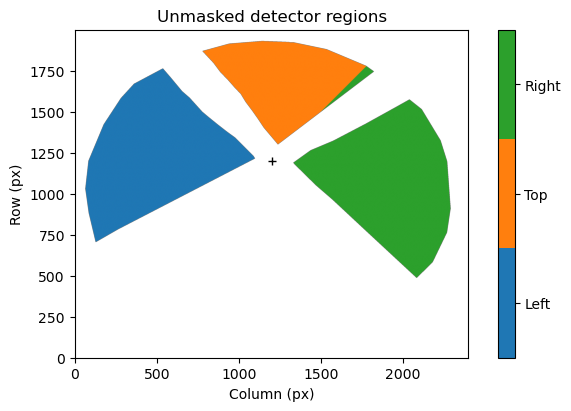

In [95]:
# 4b. Check the left/top/right partition against the painted beamstop mask
from matplotlib.colors import ListedColormap
region_map = np.full((height, width), np.nan)
for index, name in enumerate(("left", "top", "right")):
    region_map[region_masks[name] & ~mask & original_annulus] = index
region_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
artist = ax.imshow(np.ma.masked_invalid(region_map), origin="lower", vmin=-0.5, vmax=2.5,
                   cmap=ListedColormap(["tab:blue", "tab:orange", "tab:green"]))
ax.plot(center_x, center_y, "+", color="black")
ax.set(xlabel="Column (px)", ylabel="Row (px)", title="Unmasked detector regions")
colorbar = region_figure.colorbar(artist, ax=ax, ticks=[0, 1, 2])
colorbar.ax.set_yticklabels(["Left", "Top", "Right"])
region_figure.savefig(output_folder / "beamstop_regions.png", dpi=180)
plt.show()

In [96]:
# 5. Load one zone at a time; compute profiles and keep small display arrays
records = []
for prefix in prefixes:
    for zone in tqdm(zones, desc=prefix, unit="zone"):
        filename = f"{prefix}_Zone{zone:02d}.txt"
        record = dict(prefix=prefix, zone=int(zone), filename=filename, available=False,
                      shown=None, radial=np.full(len(radii), np.nan),
                      azimuthal=np.full(len(angles), np.nan),
                      radial_count=np.zeros(len(radii), dtype=int),
                      azimuthal_count=np.zeros(len(angles), dtype=int),
                      total_counts=np.nan, asymmetry=np.nan, angular_mean=np.nan, angular_std=np.nan)
        record["region_mean"] = {name: np.nan for name in region_angles}
        record["region_count"] = {name: 0 for name in region_angles}
        record["region_sum"] = {name: np.nan for name in region_angles}
        record["region_asymmetry"] = np.nan
        try:
            image = np.loadtxt(input_folder / filename)
            # Exclude red mask pixels BEFORE binning; never turn them into valid zeros.
            valid = np.isfinite(image) & ~mask & original_annulus
            # Region metric uses original pixels, so it is independent of image binning.
            for region_name, region_mask in region_masks.items():
                use = valid & region_mask
                pixel_count = int(use.sum())
                record["region_count"][region_name] = pixel_count
                record["region_sum"][region_name] = float(image[use].sum())
                if pixel_count:
                    record["region_mean"][region_name] = float(image[use].mean())
            top = record["region_mean"]["top"]
            right = record["region_mean"]["right"]
            denominator = (right + top) / 2
            if np.isfinite(denominator) and denominator > 0:
                record["region_asymmetry"] = top / denominator
            b = image_bin_size
            cell_total = np.where(valid, image, 0).reshape(height//b, b, width//b, b).sum(axis=(1, 3))
            cell_count = valid.reshape(height//b, b, width//b, b).sum(axis=(1, 3))
            # Count-weighted cell means preserve counts per ORIGINAL valid pixel.
            count = np.bincount(radial_bin.ravel(), weights=cell_count.ravel(), minlength=len(radii))
            total = np.bincount(radial_bin.ravel(), weights=cell_total.ravel(), minlength=len(radii))
            np.divide(total, count, out=record["radial"], where=count > 0)
            record["radial_count"] = count
            count = np.bincount(angular_bin.ravel(), weights=cell_count.ravel(), minlength=len(angles))
            total = np.bincount(angular_bin.ravel(), weights=cell_total.ravel(), minlength=len(angles))
            np.divide(total, count, out=record["azimuthal"], where=count > 0)
            record["azimuthal_count"] = count
            record["total_counts"] = float(cell_total.sum())
            # Optional additional display binning, using the same valid-pixel weights.
            h, w = cell_total.shape
            d = display_bin_size if h % display_bin_size == 0 and w % display_bin_size == 0 else 1
            total = cell_total.reshape(h//d, d, w//d, d).sum(axis=(1, 3))
            count = cell_count.reshape(h//d, d, w//d, d).sum(axis=(1, 3))
            shown = np.full(total.shape, np.nan)
            np.divide(total, count, out=shown, where=count > 0)
            record["shown"] = shown
            record["available"] = True
        except (OSError, ValueError) as error:
            print(f"Skipping {filename}: {error}")
        records.append(record)

26-11-09_00045_TDC_2D_chopper:   0%|          | 0/6 [00:00<?, ?zone/s]

In [97]:
# 6. Asymmetry: std / mean on the SAME angular bins across available zones/files
common_bins = np.ones(len(angles), dtype=bool)
for record in records:
    if record["available"]:
        common_bins &= ((record["azimuthal_count"] >= np.maximum(min_pixels, min_coverage * possible_counts))
                        & np.isfinite(record["azimuthal"]))
for record in records:
    if record["available"] and common_bins.sum() >= 2:
        values = record["azimuthal"][common_bins]
        record["angular_mean"] = float(np.mean(values))
        record["angular_std"] = float(np.std(values))
        if record["angular_mean"] > 0:
            record["asymmetry"] = record["angular_std"] / record["angular_mean"]
print("Common angular bins:", common_bins.sum(), "/", len(angles))
# Sparse zones can have large noise-driven asymmetry. All-zero zones remain NaN.
# This is full-image angular intensity variation, including background/geometry.
# Raw counts are not corrected for the different time-gate durations.

Common angular bins: 38 / 72


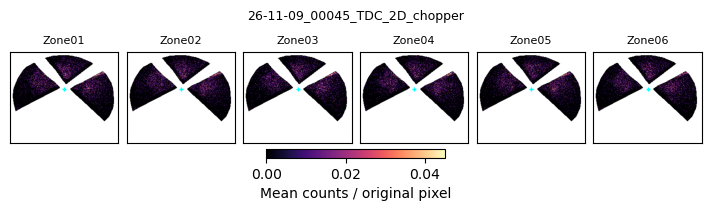

In [103]:
# 7. Zone scattering patterns, Zone01 -> Zone06 side by side
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix]
    positive = [r["shown"][np.isfinite(r["shown"]) & (r["shown"] > 0)]
                for r in selected if r["available"]]
    positive = np.concatenate(positive) if positive else np.array([])
    vmax = image_vmax if image_vmax is not None else (
        np.percentile(positive, upper_percentile) if positive.size else 1)
    fig, axes = plt.subplots(1, len(zones), figsize=(7, 2), squeeze=False, constrained_layout=True)
    artist = None
    for ax, record in zip(axes.flat, selected):
        ax.set_title(f"Zone{record['zone']:02d}", fontsize=8)
        if record["available"]:
            artist = ax.imshow(record["shown"], origin="lower", cmap="magma", vmin=0, vmax=max(vmax, 1e-12),
                               extent=(-0.5, width-0.5, -0.5, height-0.5))
            ax.plot(center_x, center_y, "+", color="cyan", markersize=3)
        else:
            ax.text(.5, .5, "Missing", ha="center", transform=ax.transAxes, fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(prefix, fontsize=9)
    if artist is not None:
        fig.colorbar(artist, ax=list(axes.flat), orientation="horizontal", shrink=.8,
                     fraction=.08, label="Mean counts / original pixel")
    fig.savefig(output_folder / f"{prefix}_zone_patterns.png", dpi=200)
    plt.show()

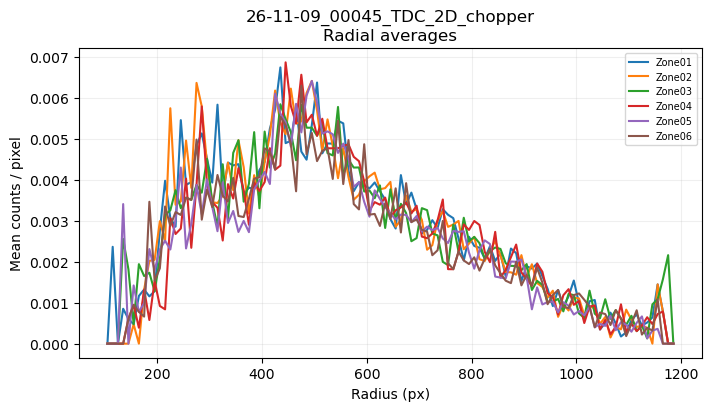

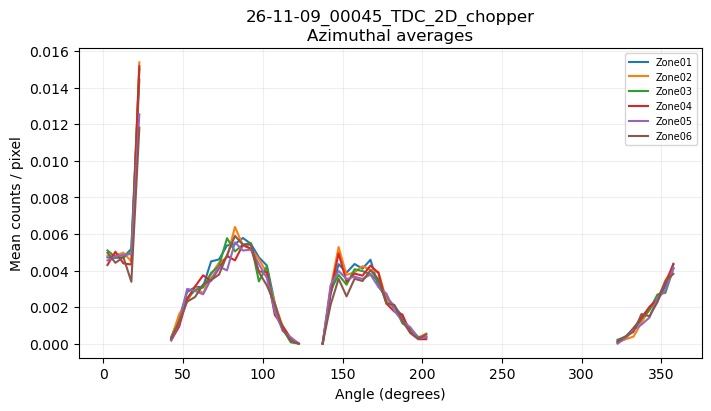

In [99]:
# 8. Radial and azimuthal averages: one line per zone, one figure per acquisition
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix and r["available"]]
    for kind, coordinate, xlabel in [("radial", radii, "Radius (px)"),
                                     ("azimuthal", angles, "Angle (degrees)")]:
        fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
        for record in selected:
            ax.plot(coordinate, record[kind], label=f"Zone{record['zone']:02d}")
        ax.set(xlabel=xlabel, ylabel="Mean counts / pixel", title=f"{prefix}\n{kind.capitalize()} averages")
        ax.legend(fontsize=7)
        ax.grid(alpha=.2)
        fig.savefig(output_folder / f"{prefix}_{kind}_averages.png", dpi=180)
        plt.show()

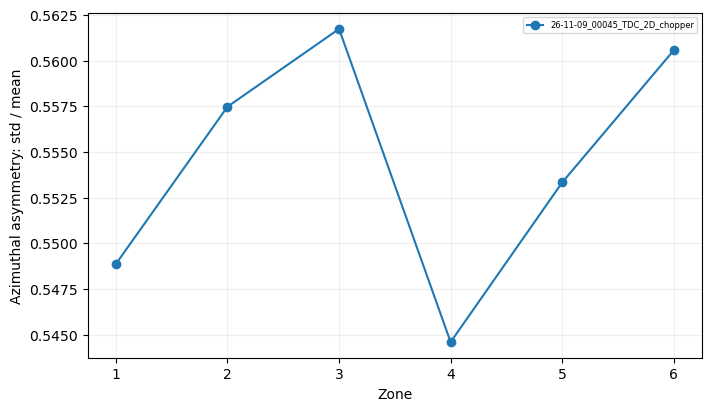

26-11-09_00045_TDC_2D_chopper_Zone01.txt counts: 4428.0 asymmetry: 0.5488691206606282
26-11-09_00045_TDC_2D_chopper_Zone02.txt counts: 4371.0 asymmetry: 0.5574725318012153
26-11-09_00045_TDC_2D_chopper_Zone03.txt counts: 4244.0 asymmetry: 0.5617287127768568
26-11-09_00045_TDC_2D_chopper_Zone04.txt counts: 4234.0 asymmetry: 0.544594625721034
26-11-09_00045_TDC_2D_chopper_Zone05.txt counts: 4074.0 asymmetry: 0.5533297656842201
26-11-09_00045_TDC_2D_chopper_Zone06.txt counts: 3986.0 asymmetry: 0.5605613429245467


In [100]:
# 9. Compare asymmetry across zones (one line per acquisition)
asymmetry_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix]
    ax.plot([r["zone"] for r in selected], [r["asymmetry"] for r in selected], "o-", label=prefix)
ax.set(xlabel="Zone", ylabel="Azimuthal asymmetry: std / mean", xticks=zones)
ax.legend(fontsize=6)
ax.grid(alpha=.2)
plt.show()
asymmetry_figure.savefig(output_folder / f"zone_asymmetry_{comparison_tag}.png", dpi=180)
for record in records:
    print(record["filename"], "counts:", record["total_counts"], "asymmetry:", record["asymmetry"])

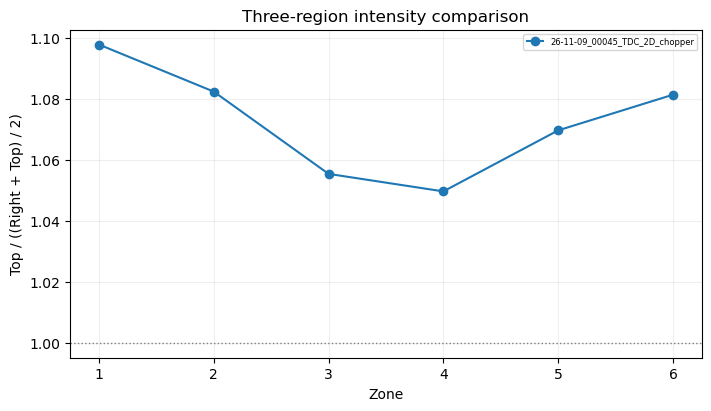

In [101]:
# 9b. Additional region asymmetry, using mean intensity per valid pixel
region_asymmetry_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix]
    ax.plot([r["zone"] for r in selected], [r["region_asymmetry"] for r in selected], "o-", label=prefix)
ax.axhline(1, color="gray", linestyle=":", linewidth=1)
ax.set(xlabel="Zone", ylabel="Top / ((Right + Top) / 2)", xticks=zones,
       title="Three-region intensity comparison")
ax.legend(fontsize=6)
ax.grid(alpha=.2)
plt.show()
region_asymmetry_figure.savefig(output_folder / f"zone_region_asymmetry_{comparison_tag}.png", dpi=180)

In [102]:
# 10. Save numerical profiles, common angular bins, and asymmetry tables
for record in records:
    stem = Path(record["filename"]).stem
    np.savetxt(radial_folder / f"{stem}_radial.csv",
               np.c_[radii, record["radial"], record["radial_count"]], delimiter=",", comments="",
               header="radius_px,mean_counts_per_pixel,valid_pixels")
    np.savetxt(azimuthal_folder / f"{stem}_azimuthal.csv",
               np.c_[angles, record["azimuthal"], record["azimuthal_count"], common_bins],
               delimiter=",", comments="", header="angle_deg,mean_counts_per_pixel,valid_pixels,used_for_asymmetry")
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix]
    np.savetxt(azimuthal_folder / f"{prefix}_asymmetry.csv",
               [[r["zone"], r["total_counts"], r["angular_mean"], r["angular_std"], r["asymmetry"], r["available"]]
                for r in selected], delimiter=",", comments="",
               header="zone,total_unmasked_counts,angular_mean,angular_std,std_over_mean,available")
# Separate table preserves all three region measurements and their pixel counts.
for prefix in prefixes:
    selected = [r for r in records if r["prefix"] == prefix]
    table = [[r["zone"], r["region_asymmetry"],
              r["region_mean"]["left"], r["region_mean"]["top"], r["region_mean"]["right"],
              r["region_count"]["left"], r["region_count"]["top"], r["region_count"]["right"],
              r["region_sum"]["left"], r["region_sum"]["top"], r["region_sum"]["right"]]
             for r in selected]
    np.savetxt(azimuthal_folder / f"{prefix}_region_asymmetry.csv", table, delimiter=",", comments="",
               header="zone,top_over_mean_right_top,left_mean,top_mean,right_mean,left_pixels,top_pixels,right_pixels,left_sum,top_sum,right_sum")
settings = dict(prefixes=prefixes, zones=zones.tolist(), center_xy=[center_x, center_y],
                radii=[inner_radius, outer_radius], radial_bin_width=radial_bin_width,
                image_bin_size=image_bin_size, display_bin_size=display_bin_size,
                angular_bin_width=angular_bin_width, min_pixels=min_pixels, min_coverage=min_coverage,
                mask_path=str(mask_path) if mask_path is not None else None,
                common_angles_deg=angles[common_bins].tolist(),
                metric="population std / mean on common angular bins",
                region_angles=region_angles, region_metric="top / ((right + top) / 2)",
                region_intensity="mean counts per original valid pixel")
(azimuthal_folder / f"zone_comparison_{comparison_tag}_settings.json").write_text(json.dumps(settings, indent=2)+"\n")
print("Plots:", output_folder.resolve())
print("Numerical data:", radial_folder.resolve(), azimuthal_folder.resolve())

Plots: /Users/riccardo/Github/SEXTANTS_261105/output/mcp
Numerical data: /Users/riccardo/Github/SEXTANTS_261105/output/mcp/radial /Users/riccardo/Github/SEXTANTS_261105/output/mcp/azimuthal
